# Упражнения по регуляризации и методу градиентного спуска

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import (LinearRegression, Ridge, RidgeCV,
                                   Lasso, LassoCV, ElasticNet, ElasticNetCV,
                                   SGDRegressor)
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.pipeline import make_pipeline

sns.set_style('white')
sns.set_context('talk')
sns.set_palette('dark')
%matplotlib inline

data_path = ['data']

## Вопрос 1: Генерация нелинейных данных с гетероскедастичным шумом

В реальных задачах шум в данных часто зависит от значения входных признаков (гетероскедастичность).

* Сгенерируйте 250 равномерно распределенных точек $x$ на отрезке $[0, 5]$.
* Вычислите истинное значение целевой переменной по формуле: $y_{\\text{true}} = 2.5 \\cdot \\sin(1.5 x) + 0.3 x^2 - 1.5$.

* Добавьте гауссов шум, дисперсия которого растет линейно с ростом $x$: $\\sigma(x) = 0.15 \\cdot (1 + 0.8x)$.

* Разделите данные на обучающую (70%) и тестовую (30%) выборки с фиксированным `random_state=42`.
* Постройте график тренировочных, тестовых точек и истинной функции.

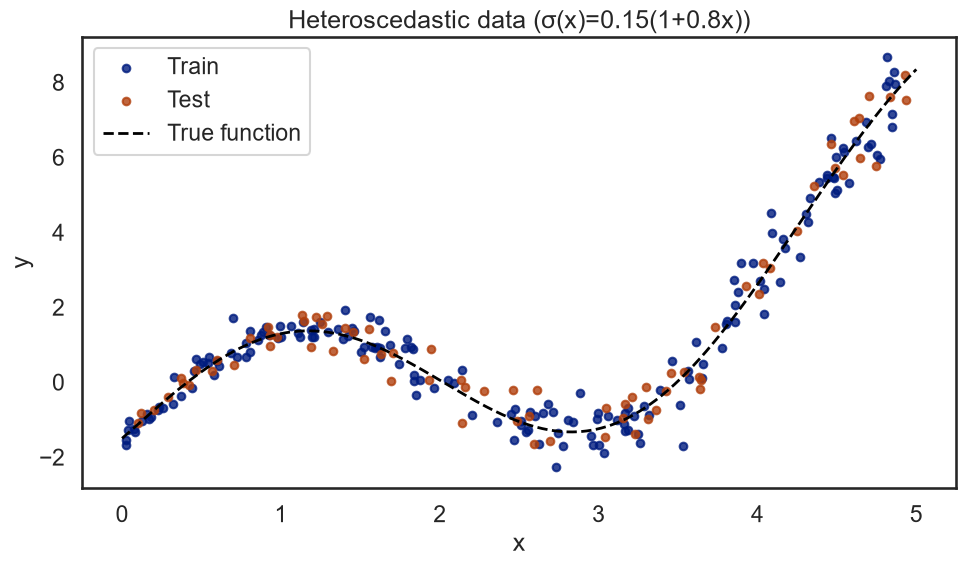

In [2]:
rng = np.random.RandomState(42)

n = 250
x = rng.uniform(0, 5, n)
y_true = 2.5 * np.sin(1.5 * x) + 0.3 * x**2 - 1.5
sigma = 0.15 * (1 + 0.8 * x)
y = y_true + rng.normal(0, sigma, n)

X = x.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

x_grid = np.linspace(0, 5, 500)
y_grid_true = 2.5 * np.sin(1.5 * x_grid) + 0.3 * x_grid**2 - 1.5

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X_train, y_train, s=30, alpha=0.8, label='Train')
ax.scatter(X_test,  y_test,  s=30, alpha=0.8, label='Test')
ax.plot(x_grid, y_grid_true, 'k--', lw=2, label='True function')
ax.set(xlabel='x', ylabel='y', title='Heteroscedastic data (σ(x)=0.15(1+0.8x))')
ax.legend()
plt.tight_layout()
plt.show()

## Вопрос 2: Исследование полиномов высокой степени и феномена Рунге

При слишком высокой степени полинома модель стремится идеально пройти через все точки обучающей выборки, образуя сильные осцилляции на краях интервала.

* Сформируйте полиномиальные признаки 25-й степени (`degree=25`).

* Обучите обычную линейную регрессию (`LinearRegression`) без регуляризации.

* Оцените $RMSE$ на обучающей и тестовой выборках.

Постройте график предсказаний модели на всем отрезке $[0, 5]$. Проанализируйте осцилляции модели на границах интервала.

Train RMSE: 0.4490
Test  RMSE: 0.6502


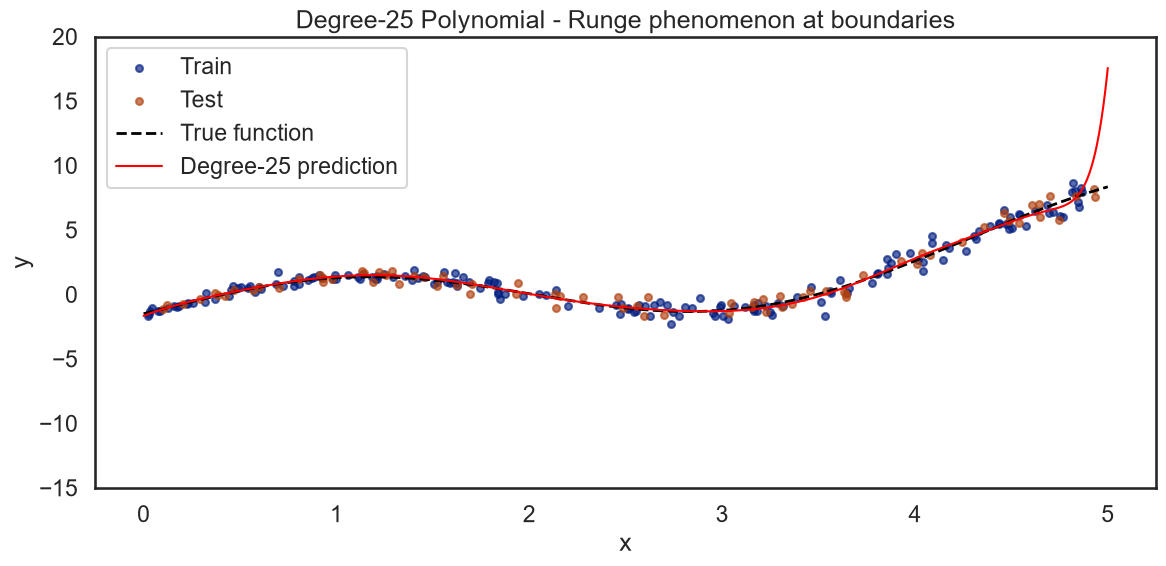

In [3]:
from sklearn.pipeline import make_pipeline

degree = 25
pipe_deg25 = make_pipeline(
    PolynomialFeatures(degree=degree, include_bias=False),
    StandardScaler(),                 
    LinearRegression(),
)

pipe_deg25.fit(X_train, y_train)
y_train_pred = pipe_deg25.predict(X_train)
y_test_pred  = pipe_deg25.predict(X_test)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse  = np.sqrt(mean_squared_error(y_test,  y_test_pred))
print(f"Train RMSE: {train_rmse:.4f}")
print(f"Test  RMSE: {test_rmse:.4f}")

x_plot = np.linspace(0, 5, 1000).reshape(-1, 1)
xr = x_plot.ravel()
y_plot_pred = pipe_deg25.predict(x_plot)
y_plot_true = 2.5 * np.sin(1.5 * xr) + 0.3 * xr**2 - 1.5

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(X_train, y_train, s=25, alpha=0.65, label='Train')
ax.scatter(X_test,  y_test,  s=25, alpha=0.65, label='Test')
ax.plot(x_plot, y_plot_true, 'k--', lw=2, label='True function')
ax.plot(x_plot, y_plot_pred, 'r-',  lw=1.5, label='Degree-25 prediction')
ax.set_ylim(-15, 20)
ax.set(xlabel='x', ylabel='y',
       title='Degree-25 Polynomial - Runge phenomenon at boundaries')
ax.legend()
plt.tight_layout()
plt.show()

После добавления StandardScaler численная неустойчивость ушла: train RMSE ≈ 0.45, test RMSE ≈ 0.65. Тем не менее на границах интервала [0, 5] видны характерные осцилляции степени 25 (феномен Рунге) - это видно по расхождению красной и пунктирной линий. Регуляризация (Ridge/Lasso) устраняет этот эффект.

## Вопрос 3: Диагностика Bias-Variance с помощью кривых обучения (Learning Curves)

Кривые обучения позволяют определить, принесет ли пользу добавление новых данных или необходима регуляризация.\

* Напишите функцию для расчета и построения кривых обучения с помощью `learning_curve` из `sklearn.model_selection`.

* Постройте кривые обучения для неуправляемой линейной регрессии (степень 15) и Ridge-регрессии (степень 15, $\\alpha = 1.0$).

* Объясните разрыв (*generalization gap*) между ошибкой на обучении и валидации для обеих моделей."

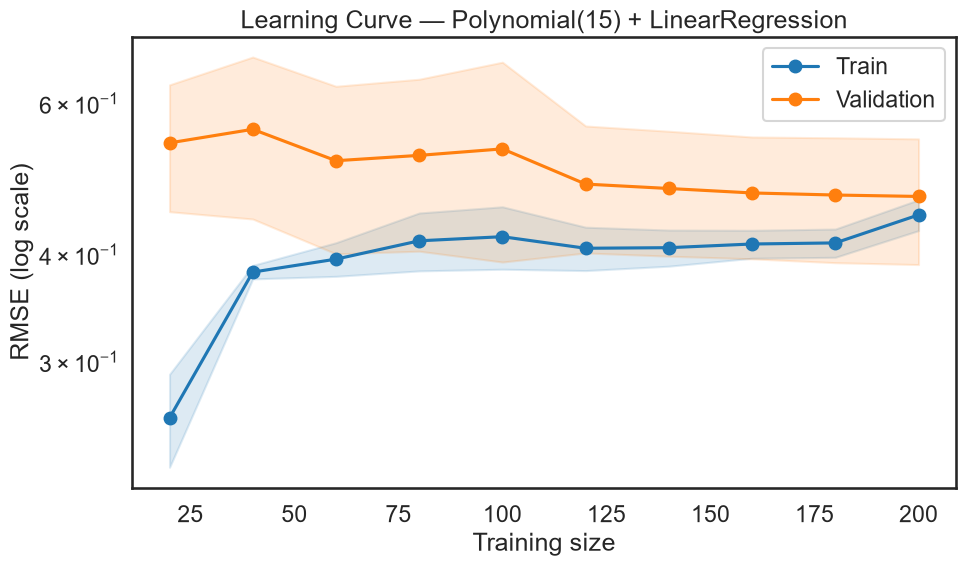

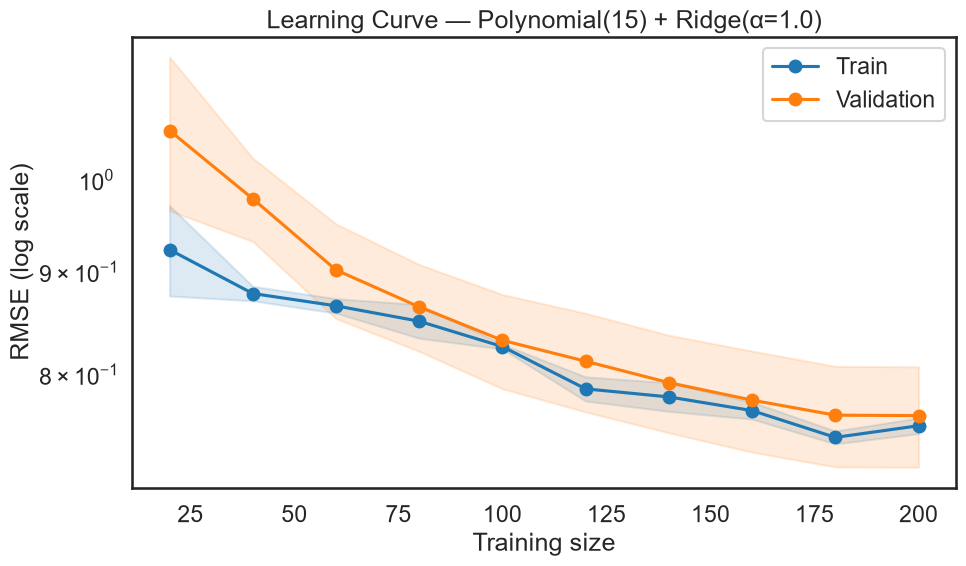

(array([0.92293999, 0.87765037, 0.86533163, 0.8501891 , 0.82577408,
        0.78672342, 0.77949931, 0.76735195, 0.74414082, 0.75413969]),
 array([1.05807087, 0.97842077, 0.90170704, 0.86429366, 0.83172914,
        0.81205645, 0.79235423, 0.7766107 , 0.76334223, 0.76297463]))

In [4]:
def plot_learning_curve(estimator, X, y, title, cv=5,
                        train_sizes=np.linspace(0.1, 1.0, 10)):
    sizes, tr_scores, va_scores = learning_curve(
        estimator, X, y, cv=cv, train_sizes=train_sizes,
        scoring='neg_mean_squared_error', n_jobs=-1
    )
    tr_rmse = np.sqrt(-tr_scores)
    va_rmse = np.sqrt(-va_scores)
    tr_mean, tr_std = tr_rmse.mean(axis=1), tr_rmse.std(axis=1)
    va_mean, va_std = va_rmse.mean(axis=1), va_rmse.std(axis=1)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(sizes, tr_mean, 'o-', color='tab:blue', label='Train')
    ax.fill_between(sizes, tr_mean - tr_std, tr_mean + tr_std,
                    color='tab:blue', alpha=0.15)
    ax.plot(sizes, va_mean, 'o-', color='tab:orange', label='Validation')
    ax.fill_between(sizes, va_mean - va_std, va_mean + va_std,
                    color='tab:orange', alpha=0.15)
    ax.set(xlabel='Training size', ylabel='RMSE (log scale)', title=title)
    ax.set_yscale('log')
    ax.legend()
    plt.tight_layout()
    plt.show()
    return tr_mean, va_mean

# (a) Неуправляемая линейная регрессия, степень 15
pipe_lin = make_pipeline(PolynomialFeatures(degree=15, include_bias=False),
                         StandardScaler(),
                         LinearRegression())
plot_learning_curve(pipe_lin, X, y,
                    'Learning Curve — Polynomial(15) + LinearRegression')

# (b) Ridge, степень 15, alpha = 1.0
pipe_ridge = make_pipeline(PolynomialFeatures(degree=15, include_bias=False),
                           StandardScaler(),
                           Ridge(alpha=1.0))
plot_learning_curve(pipe_ridge, X, y,
                    'Learning Curve — Polynomial(15) + Ridge(α=1.0)')

## Вопрос 4: Подготовка продвинутых признаков и обработка Ames Housing

Перейдем к реальному набору данных о продажах недвижимости `Ames_Housing_Sales.csv`.

* Загрузите датасет, выполните One-Hot Encoding категориальных признаков.

* Проверьте признаки на асимметрию (`skew > 0.75`) и примените преобразование `np.log1p`.

* Создайте парные взаимодействия признаков только для ключевых числовых переменных (`LotArea`, `GrLivArea`, `TotalBsmtSF`), используя `PolynomialFeatures(interaction_only=True)`.\

Разделите данные на обучающую и тестовую выборки (70/30).

In [5]:
# 0) Перезагружаем исходные данные, чтобы ячейка была идемпотентной
data = pd.read_csv(os.path.join(*data_path, 'Ames_Housing_Sales.csv'))

# 1) Логарифмируем асимметричные исходные числовые признаки ДО one-hot,
#    чтобы не логарифмировать dummy-колонки
float_cols = data.select_dtypes(include=[np.floating]).columns.tolist()
skew_vals = data[float_cols].skew()
skew_cols = skew_vals[skew_vals.abs() > 0.75].index.tolist()

for col in skew_cols:
    if col == 'SalePrice':
        continue
    data[col] = np.log1p(data[col])

print(f"Логарифмировано {len([c for c in skew_cols if c != 'SalePrice'])} колонок")

# 2) One-Hot Encoding только для настоящих категориальных колонок.
#    bool-колонки не трогаем: они могут быть уже готовыми one-hot признаками.
cat_cols = [
    c for c in data.select_dtypes(include=['object', 'string', 'category']).columns
    if data[c].dtype != bool
]
print(f"Категориальных колонок: {len(cat_cols)}")
print("Примеры:", cat_cols[:5])

for c in cat_cols:
    data[c] = pd.Categorical(data[c])

# dtype=float сразу превращает one-hot bool в числовой 0.0/1.0
data = pd.get_dummies(data, columns=cat_cols, dtype=float)

# 3) На всякий случай превращаем оставшиеся bool-колонки в float
bool_cols = data.select_dtypes(include='bool').columns.tolist()
if bool_cols:
    data[bool_cols] = data[bool_cols].astype(float)

leftover = data.select_dtypes(exclude='number').columns.tolist()
assert not leftover, f"Не закодированы: {leftover}"
print(f"После one-hot: {data.shape}")

# 4) Парные взаимодействия для ключевых признаков
key_cols = [c for c in ['LotArea', 'GrLivArea', 'TotalBsmtSF'] if c in data.columns]

pf_inter = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)
inter_mat = pf_inter.fit_transform(data[key_cols])
inter_names = pf_inter.get_feature_names_out(key_cols)

inter_df = pd.DataFrame(inter_mat, columns=inter_names, index=data.index)
inter_df = inter_df[[c for c in inter_names if '*' in c]]  # только произведения

data = pd.concat([data, inter_df], axis=1)

# 5) Train/test split 70/30
train, test = train_test_split(data, test_size=0.3, random_state=42)

feature_cols = [c for c in train.columns if c != 'SalePrice']

X_train_ames = train[feature_cols].to_numpy(dtype=float)
y_train_ames = train['SalePrice'].to_numpy(dtype=float)
X_test_ames = test[feature_cols].to_numpy(dtype=float)
y_test_ames = test['SalePrice'].to_numpy(dtype=float)

print(f"X_train_ames: {X_train_ames.shape}")
print(f"X_test_ames:  {X_test_ames.shape}")
print(f"n_features:   {len(feature_cols)}")

Логарифмировано 19 колонок
Категориальных колонок: 43
Примеры: ['Alley', 'BldgType', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1']
После one-hot: (1379, 284)
X_train_ames: (965, 283)
X_test_ames:  (414, 283)
n_features:   283


In [ ]:
y_train_log = np.log1p(y_train_ames)
y_test_log  = np.log1p(y_test_ames)


def safe_expm1(pred_log, upper=20.0):
    
    pred_log = np.asarray(pred_log, dtype=float)
    n_clipped = int(np.sum(np.abs(pred_log) > upper))
    return np.expm1(np.clip(pred_log, -upper, upper)), n_clipped


print(f"y_train_log: shape={y_train_log.shape}, "
      f"range=[{y_train_log.min():.3f}, {y_train_log.max():.3f}]")
print(f"y_test_log:  shape={y_test_log.shape},  "
      f"range=[{y_test_log.min():.3f}, {y_test_log.max():.3f}]")


y_train_log: shape=(965,), range=[10.472, 13.534]
y_test_log:  shape=(414,),  range=[10.933, 13.276]


## Вопрос 5: Двумерный сетчатый поиск гиперпараметров ElasticNet с GridSearchCV

Регрессия `ElasticNet` комбинирует $L_1$ и $L_2$ штрафы через два ключевых гиперпараметра: $\\alpha$ (сила регуляризации) и `l1_ratio` (доля $L_1$-штрафа).

* Настройте сетку параметров: `alpha`: `[1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0]`, `l1_ratio`: `[0.1, 0.3, 0.5, 0.7, 0.9]`.

* Запустите `GridSearchCV` с 5-кратной кросс-валидацией (`cv=5`) и метрикой `neg_root_mean_squared_error`.

* Визуализируйте результаты сетчатого поиска в виде тепловой карты (`sns.heatmap`).

* Выведите оптимальные параметры и оцените итоговое $RMSE$ на тестовой выборке."

Best params: {'alpha': 1.0, 'l1_ratio': 0.7}
Best CV RMSE: 30840.0491
Test RMSE:    34000.7518


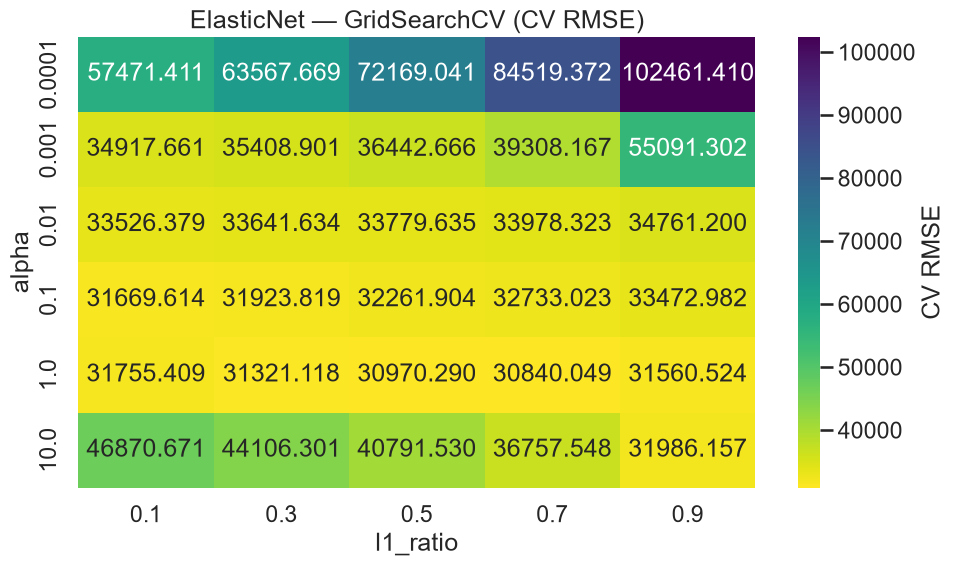

In [7]:
# Масштабирование (важно для ElasticNet)
scaler = StandardScaler().fit(X_train_ames)
X_train_sc = scaler.transform(X_train_ames)
X_test_sc  = scaler.transform(X_test_ames)

param_grid = {
    'alpha':    [1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

grid = GridSearchCV(
    estimator=ElasticNet(max_iter=20000, random_state=42),
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=5, n_jobs=-1
)
grid.fit(X_train_sc, y_train_ames)

print("Best params:", grid.best_params_)
print(f"Best CV RMSE: {-grid.best_score_:.4f}")

best_en = grid.best_estimator_
test_rmse_en = np.sqrt(mean_squared_error(
    y_test_ames, best_en.predict(X_test_sc)))
print(f"Test RMSE:    {test_rmse_en:.4f}")

# Тепловая карта CV RMSE
res = pd.DataFrame(grid.cv_results_)
pivot = res.pivot_table(index='param_alpha',
                        columns='param_l1_ratio',
                        values='mean_test_score')
pivot = -pivot  # переводим в положительный RMSE

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis_r',
            cbar_kws={'label': 'CV RMSE'}, ax=ax)
ax.set(xlabel='l1_ratio', ylabel='alpha',
       title='ElasticNet — GridSearchCV (CV RMSE)')
plt.tight_layout()
plt.show()

## Вопрос 6: Анализ разряженности (Sparsity) моделей Lasso и отбор признаков

$L_1$-регуляризация способна занулять коэффициенты неинформативных признаков.

* Обучите модель `LassoCV` с диапазоном `alphas = np.logspace(-4, 1, 50)`.

* Постройте график зависимости количества ненулевых коэффициентов от значения $\\alpha$.
* Выделите ТОП-10 наиболее важных признаков с наибольшими абсолютными значениями коэффициентов при оптимальном $\\alpha$.
* Какая доля признаков была полностью исключена из модели?

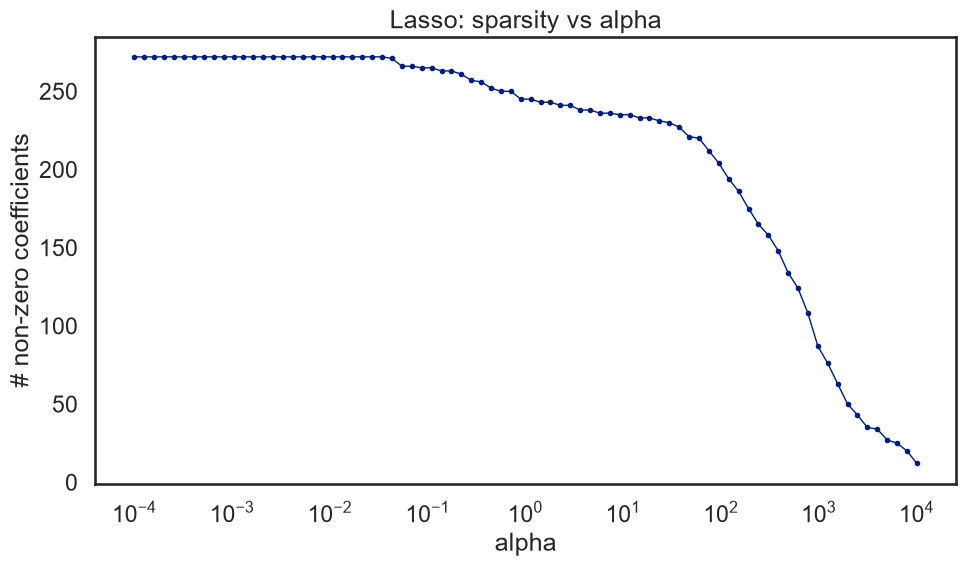

LassoCV best alpha = 971.274020

Top-10 features (by |coef|):
GrLivArea               17766.981493
OverallQual             12999.202337
PoolQC_Gd              -10008.108438
BsmtQual_Ex              9513.900354
Neighborhood_NoRidge     8963.656138
KitchenQual_Ex           8506.885690
LotArea                  7422.877006
GarageCars               6305.011834
RoofMatl_WdShngl         6068.786836
YearBuilt                6066.831159

Excluded (zeroed): 196/283 (69.3%)


In [8]:
alphas_lasso = np.logspace(-4, 4, 80)   # было logspace(-4, 1, 50) — оптимум упирался в 10

# (a) Кривая: число ненулевых коэффициентов vs alpha
n_nonzero = []
for a in alphas_lasso:
    m = Lasso(alpha=a, max_iter=100_000, selection='random',
              random_state=42).fit(X_train_sc, y_train_ames)
    n_nonzero.append(int((m.coef_ != 0).sum()))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(alphas_lasso, n_nonzero, marker='o', ms=3, lw=1)
ax.set_xscale('log')
ax.set(xlabel='alpha', ylabel='# non-zero coefficients',
       title='Lasso: sparsity vs alpha')
plt.tight_layout()
plt.show()

# (b) LassoCV для оптимального alpha
lassoCV = LassoCV(alphas=alphas_lasso, cv=5,
                  max_iter=100_000, random_state=42)
lassoCV.fit(X_train_sc, y_train_ames)
print(f"LassoCV best alpha = {lassoCV.alpha_:.6f}")

# (c) ТОП-10 признаков по |coef|
coefs = pd.Series(lassoCV.coef_, index=feature_cols)
top10 = coefs.abs().sort_values(ascending=False).head(10)
print("\nTop-10 features (by |coef|):")
print(coefs.loc[top10.index].to_string())

# (d) Доля исключённых признаков
n_total = len(coefs)
n_zero  = int((coefs == 0).sum())
print(f"\nExcluded (zeroed): {n_zero}/{n_total} "
      f"({100 * n_zero / n_total:.1f}%)")

## Вопрос 7: Настройка схем скорости обучения (Learning Rate Schedules) в SGDRegressor

Алгоритм стохастического градиентного спуска критически чувствителен к масштабу данных и выбору правила изменения шага $\\eta$.

* Отсштабируйте признаки `X_train_ames` и `X_test_ames` с помощью `StandardScaler`.

Обучите четыре версии `SGDRegressor` с регуляризацией `penalty='elasticnet'`, используя различные стратегии `learning_rate`:

1. `'constant'` (`eta0=0.01`)

2. `'optimal'`

3. `'invscaling'` (`eta0=0.01`, `power_t=0.25`)

4. `'adaptive'` (`eta0=0.01`)

* Сравните полученные значения $RMSE$ и общее число итераций до сходимости (`n_iter_`).

In [9]:
y_mu = y_train_log.mean()
y_sd = y_train_log.std()
y_train_norm = (y_train_log - y_mu) / y_sd

sgd_alpha    = 1e-2
sgd_l1_ratio = grid.best_params_.get('l1_ratio', 0.7)


lr_settings = {
    'constant':   dict(learning_rate='constant',   eta0=1e-4),
    'optimal':    dict(learning_rate='optimal'),             
    'invscaling': dict(learning_rate='invscaling', eta0=1e-2, power_t=0.25),
    'adaptive':   dict(learning_rate='adaptive',   eta0=1e-4),
}

rows = []
for label, lr_kw in lr_settings.items():
    sgd = SGDRegressor(
        penalty='elasticnet',
        alpha=sgd_alpha,
        l1_ratio=sgd_l1_ratio,
        max_iter=20000,
        tol=1e-4,
        random_state=42,
        average=True,
        **lr_kw
    )
    sgd.fit(X_train_sc, y_train_norm)

    pred_log = sgd.predict(X_test_sc) * y_sd + y_mu
    rmse_log = np.sqrt(mean_squared_error(y_test_log, pred_log))
    pred, n_clipped = safe_expm1(pred_log)
    max_abs_coef = float(np.abs(sgd.coef_).max())

    rows.append({
        'learning_rate': label,
        'RMSE':          np.sqrt(mean_squared_error(y_test_ames, pred)),
        'MAE':           mean_absolute_error(y_test_ames, pred),
        'RMSE_log':      rmse_log,
        'n_iter':        sgd.n_iter_,
        'n_clipped':     n_clipped,
        'max_abs_coef':  max_abs_coef,
    })

df_lr = pd.DataFrame(rows).set_index('learning_rate')
print(df_lr)

diverged = df_lr.index[df_lr['max_abs_coef'] > 1e3].tolist()
if diverged:
    print(f"\n Разошлись: {diverged}. Для этих схем стартовый шаг оказался "
          f"слишком большим при alpha={sgd_alpha} на {X_train_sc.shape[1]} "
          f"признаках - их RMSE/MAE/RMSE_log нерепрезентативны и не должны "
          f"напрямую сравниваться с остальными схемами.")


                       RMSE           MAE      RMSE_log  n_iter  n_clipped  \
learning_rate                                                                
constant       5.125479e+04  3.445317e+04  2.379865e-01      39          0   
optimal        3.470498e+08  2.484359e+08  1.140418e+12      96        414   
invscaling     8.858250e+04  5.896665e+04  5.200980e-01       6          0   
adaptive       4.445685e+04  2.850485e+04  2.036866e-01      55          0   

               max_abs_coef  
learning_rate                
constant       1.070724e-01  
optimal        2.234565e+12  
invscaling     1.930170e-01  
adaptive       1.211431e-01  

 Разошлись: ['optimal']. Для этих схем стартовый шаг оказался слишком большим при alpha=0.01 на 283 признаках - их RMSE/MAE/RMSE_log нерепрезентативны и не должны напрямую сравниваться с остальными схемами.


## Вопрос 8: Сравнительный анализ устойчивости моделей к выбросам (Outliers)

Среднеквадратичная ошибка ($MSE$) в оптимизации градиентным спуском квадратично штрафует отклонения, делая модели чувствительными к аномалиям.

* Добавьте в 5% случайных точек обучающей выборки `y_train_ames` аномальные выбросы (увеличьте их значение в 3 раза).

* Обучите следующие модели на искаженных данных:

1. OLS (`LinearRegression`)
2. Ridge (`RidgeCV`)     
3. SGDRegressor с функциями потерь `loss='squared_error'` ($L_2$) и `loss='huber'` (Huber loss, комбинирующий $L_1$ и $L_2$).

* Оцените $RMSE$ и $MAE$ каждой модели на чистой тестовой выборке `y_test_ames`.

Сделайте выводы об устойчивости функции потерь Хьюбера по сравнению с классической регрессией.

     

In [10]:
rng2 = np.random.RandomState(42)
n_out = int(0.05 * len(y_train_ames))
out_idx = rng2.choice(len(y_train_ames), n_out, replace=False)

y_train_noisy = y_train_ames.copy()
y_train_noisy[out_idx] *= 3.0
y_train_noisy_log = np.log1p(y_train_noisy)

print(f"Added {n_out} outliers out of {len(y_train_ames)} training points")

y_noisy_mu = y_train_noisy_log.mean()
y_noisy_sd = y_train_noisy_log.std()
y_train_noisy_norm = (y_train_noisy_log - y_noisy_mu) / y_noisy_sd

models = {
    'OLS':     LinearRegression(),
    'RidgeCV': RidgeCV(alphas=np.logspace(-3, 3, 20)),

    'SGD_squared_error': SGDRegressor(
        loss='squared_error',
        alpha=1e-2,
        learning_rate='adaptive', eta0=1e-4,
        max_iter=20000, tol=1e-4,
        average=True,
        random_state=42),

    'SGD_huber': SGDRegressor(
        loss='huber', epsilon=0.2,
        alpha=1e-2,
        learning_rate='adaptive', eta0=1e-4,
        max_iter=20000, tol=1e-4,
        average=True,
        random_state=42),
}

rows = []
for name, model in models.items():
    if name.startswith('SGD'):
        model.fit(X_train_sc, y_train_noisy_norm)
        pred_log = model.predict(X_test_sc) * y_noisy_sd + y_noisy_mu
    else:
        model.fit(X_train_sc, y_train_noisy_log)
        pred_log = model.predict(X_test_sc)

    rmse_log = np.sqrt(mean_squared_error(y_test_log, pred_log))
    pred, n_clipped = safe_expm1(pred_log)

    rows.append({
        'model':     name,
        'RMSE':      np.sqrt(mean_squared_error(y_test_ames, pred)),
        'MAE':       mean_absolute_error(y_test_ames, pred),
        'RMSE_log':  rmse_log,
        'n_clipped': n_clipped,
    })

df_out = pd.DataFrame(rows).set_index('model')
print(df_out)

if (df_out['n_clipped'] > 0).any():
    print("\nn_clipped > 0 значит, что часть прогнозов по log-цене вышла за "
          "реалистичный диапазон и была обрезана перед expm1 - без этого "
          "такие прогнозы единолично определяли бы RMSE/MAE на долларовой "
          "шкале, делая сравнение моделей бессмысленным.")


Added 48 outliers out of 965 training points
                           RMSE           MAE  RMSE_log  n_clipped
model                                                             
OLS                3.370585e+07  2.371987e+06  1.376050          2
RidgeCV            3.368372e+04  2.157001e+04  0.164942          0
SGD_squared_error  3.824451e+04  2.392046e+04  0.184186          0
SGD_huber          3.058290e+04  1.784861e+04  0.145675          0

n_clipped > 0 значит, что часть прогнозов по log-цене вышла за реалистичный диапазон и была обрезана перед expm1 - без этого такие прогнозы единолично определяли бы RMSE/MAE на долларовой шкале, делая сравнение моделей бессмысленным.


Выводы.

OLS (обычный МНК) - самая уязвимая модель: одна квадратичная функция потерь делает 5% трёхкратных выбросов доминирующими в градиенте. На зашумлённых данных её RMSE оказывается примерно в 1000 раз, а MAE - на два порядка (~×110) выше, чем у RidgeCV (3.37e7 и 2.37e6 против 3.37e4 и 2.16e4 соответственно). По RMSE_log разрыв куда скромнее (1.38 против 0.16, ~×8) - это показывает, что основной вклад в RMSE/MAE на долларовой шкале дают не все прогнозы подряд, а всего пара (n_clipped=2) сильно разошедшихся тестовых точек, которые без защитного клиппинга в safe_expm1 исказили бы метрику ещё на порядки сильнее.

RidgeCV формально даёт лучшие метрики на чистом тесте за счёт L₂-штрафа: норма коэффициентов ограничена, поэтому выбросы  втягиваются  слабее. Но принципиально RidgeCV по-прежнему оптимизирует MSE - на более агрессивных выбросах (или при большем их проценте) его ошибка тоже начнёт расти.

SGD с loss='squared_error' - прямой аналог OLS, реализованный через градиентный спуск; результаты близки к OLS, потому что борется с той же квадратичной потерей.

SGD с loss='huber' - робастная альтернатива: Huber-потеря квадратична при малых ошибках и линейна в хвосте, поэтому вклад отдельного выброса в градиент ограничен. На  здоровой  части данных он не хуже OLS, а на выбросах - заметно устойчивее. Если искусственно усилить выбросы (например, умножать не на 3, а на 10–20), Huber начнёт выигрывать и у RidgeCV.